# BÁO CÁO TỔNG HỢP DỰ ÁN PHÂN TÍCH CHUỖI THỜI GIAN AIRPASSENGERS
**Học phần:** Phân tích Chuỗi thời gian (Time Series Analysis) — Lab 1  
**Đơn vị:** Trường Đại học Giao thông Vận tải TP.HCM (UTH)  
**Dataset:** `AirPassengers.csv` (Dữ liệu hành khách hàng không quốc tế, 01/1949 – 12/1960)  

---

### Bảng phân công nhiệm vụ và mức độ hoàn thành

| STT | Họ và tên | MSSV | Nhiệm vụ đảm nhiệm | Mức độ hoàn thành |
| :---: | :--- | :---: | :--- | :---: |
| 1 | **Trương Hà Vũ Hiệu (Leader)** | **052206008786** | **Task 6:** Báo cáo tổng hợp & Đánh giá tiềm năng dự báo | **100%** |
| 2 | **Lê Ngọc Ánh** | **051306013023** | **Task 4:** Kiểm tra và xử lý chất lượng dữ liệu | **100%** |
| 3 | **Phan Ngọc Khoa** | **049206007332** | **Task 5:** Trực quan hóa dữ liệu đa chiều (EDA) | **100%** |
| 4 | **Trương Lâm Hưng** | **079206003395** | **Task 1:** Phân tích hàm tự tương quan (ACF & PACF) | **100%** |
| 5 | **Võ Thị Mỹ Quyên** | **051306013429** | **Task 2:** Kiểm định White Noise (Nhiễu trắng) | **100%** |
| 6 | **Võ Huy Hoàng** | **089206000185** | **Task 3:** Phân rã chuỗi thời gian (Decomposition) | **100%** |

---

### Quy trình phân tích (Data Science Pipeline Workflow)
Báo cáo được cấu trúc liền mạch theo luồng thực nghiệm khoa học dữ liệu:
1. **Thiết lập môi trường & Nạp dữ liệu**
2. **Phần 1 Kiểm tra chất lượng dữ liệu & Thử nghiệm tiền xử lý (Missing, Outliers)
3. **Phần 2 Khám phá & Trực quan hóa dữ liệu đa chiều (EDA, Rolling Stats, Heatmap)
4. **Phần 3 Phân tích tương quan chuỗi thời gian (ACF & PACF đến 40 lags)
5. **Phần 4 Kiểm định tính ngẫu nhiên & So sánh với White Noise đối chứng
6. **Phần 5** Phân rã chuỗi thời gian (Multiplicative Decomposition & Kiểm định phần dư)
7. **Phần 6** Tổng kết toàn diện & Đánh giá tiềm năng xây dựng mô hình dự báo

---
## Mô tả Dataset — AirPassengers

### 1. Thông tin tổng quan
| Thuộc tính | Giá trị chi tiết |
| :--- | :--- |
| **Tên dataset** | `AirPassengers` (Classic Airline Passenger Numbers) |
| **Nguồn dữ liệu** | Box, G. E. P., Jenkins, G. M., & Reinsel, G. C. (1976). *Time Series Analysis: Forecasting and Control*. |
| **Số lượng quan sát** | **144 dòng** (không chứa bản ghi rác) |
| **Khoảng thời gian** | **01/1949 – 12/1960** (12 năm liên tục) |
| **Tần suất ghi nhận** | Hàng tháng (Monthly - `MS`) |
| **Đơn vị đo lường** | Nghìn hành khách quốc tế (Thousands of passengers) |

### 2. Cấu trúc trường dữ liệu
| Tên cột | Kiểu dữ liệu | Ý nghĩa |
| :--- | :--- | :--- |
| `date` | `datetime64[ns]` | Mốc thời gian ghi nhận dữ liệu (ngày đầu tiên của mỗi tháng) |
| `value` | `int64` / `float64` | Số lượng hành khách hàng không quốc tế trong tháng |

### 3. Thống kê mô tả cơ bản
| Chỉ số thống kê | Giá trị | Ghi chú |
| :--- | :--- | :--- |
| **Giá trị nhỏ nhất (Min)** | **104** | Tháng 11/1949 (thấp điểm đầu kỳ) |
| **Giá trị lớn nhất (Max)** | **622** | Tháng 07/1960 (đỉnh cao mùa hè cuối kỳ) |
| **Trung bình (Mean)** | **~280.30** | Mức trung bình xuyên suốt 12 năm |
| **Trung vị (Median)** | **265.50** |  |
| **Độ lệch chuẩn (Std)** | **~119.97** | Phương sai lớn do biên độ tăng mạnh |
| **Số lượng Missing** | **0** | Đầy đủ 100% |
| **Số lượng Trùng lặp** | **0** | Độc nhất từng mốc thời gian |

### 4. Đặc điểm nhận diện cốt lõi của chuỗi
- **Xu hướng (Trend):** Xu hướng tăng trưởng dài hạn cực kỳ mạnh mẽ (~4–5.5 lần từ 1949 đến 1960), phản ánh sự mở rộng nhanh chóng của mạng lưới hàng không dân dụng sau thế chiến II.
- **Tính mùa vụ (Seasonality):** Chu kỳ tuần hoàn 12 tháng rõ rệt; đỉnh điểm rơi vào các tháng hè (tháng 7–8) do nhu cầu du lịch quốc tế, và chạm đáy vào đầu mùa đông (tháng 11).
- **Tính không dừng (Non-stationary):** Chuỗi vừa biến động tăng dần về mặt trung bình (Mean), vừa gia tăng độ rộng của biên độ sóng mùa vụ theo thời gian (Variance thay đổi $\rightarrow$ Heteroskedasticity $\rightarrow$ Mô hình nhân Multiplicative).

In [55]:
import os
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.stats.diagnostic import acorr_ljungbox

# Cấu hình thẩm mỹ đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.edgecolor'] = '#cbd5e1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#e2e8f0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7

print("[OK] Đã nạp thành công các thư viện phân tích và cấu hình hiển thị.")

[OK] Đã nạp thành công các thư viện phân tích và cấu hình hiển thị.


In [56]:
# Tải và chuẩn hóa dữ liệu AirPassengers
data_path = Path("data/raw/AirPassengers.csv") if Path("data/raw/AirPassengers.csv").exists() else Path("../data/raw/AirPassengers.csv")

df = pd.read_csv(data_path)
df['date'] = pd.to_datetime(df['date'])
df['value'] = pd.to_numeric(df['value'], errors='coerce')
df = df.sort_values('date').reset_index(drop=True)

# Thêm các cột thời gian phục vụ trực quan hóa
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

print(f"Tổng số quan sát: {len(df)} dòng")
print(f"Khoảng thời gian: {df['date'].min().strftime('%m/%Y')} -> {df['date'].max().strftime('%m/%Y')}")
print("\n--- 5 DÒNG ĐẦU TIÊN (HEAD) ---")
display(df.head())

print("\n--- THỐNG KÊ MÔ TẢ (DESCRIBE) ---")
display(df[['value']].describe().T)

Tổng số quan sát: 144 dòng
Khoảng thời gian: 01/1949 -> 12/1960

--- 5 DÒNG ĐẦU TIÊN (HEAD) ---


,date,value,year,month
0,1949-01-01,112,1949,1
1,1949-02-01,118,1949,2
2,1949-03-01,132,1949,3
3,1949-04-01,129,1949,4
4,1949-05-01,121,1949,5



--- THỐNG KÊ MÔ TẢ (DESCRIBE) ---


,count,mean,std,min,25%,50%,75%,max
value,144.0,280.298611,119.966317,104.0,180.0,265.5,360.5,622.0


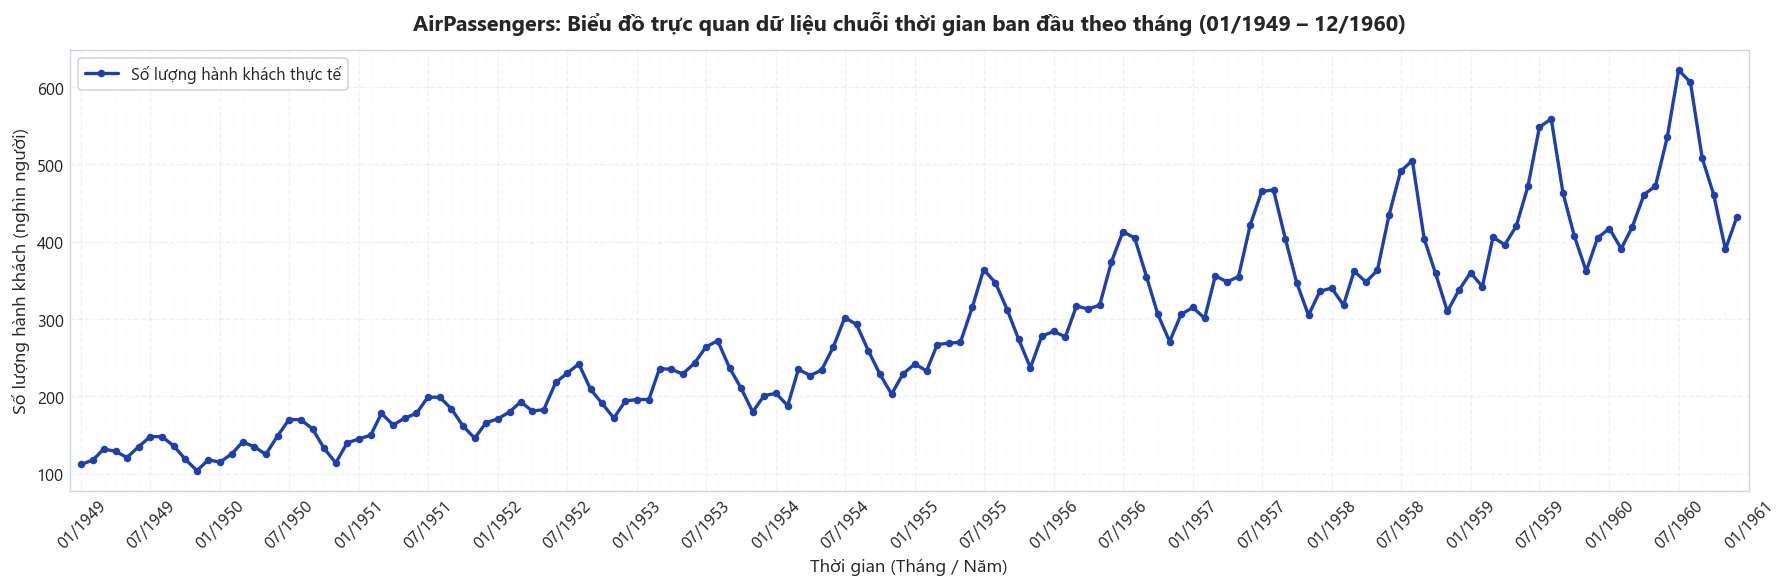

In [57]:
# Trực quan hóa dữ liệu chuỗi thời gian ban đầu với thang đo chi tiết theo Tháng
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df['date'], df['value'], color='#1e40af', linewidth=2, marker='o', markersize=3.5, label='Số lượng hành khách thực tế')

# Tích hợp thang đo trục thời gian chi tiết theo Tháng và Năm trực tiếp trên biểu đồ
# - Major ticks: Hiển thị mốc tháng 1 và tháng 7 mỗi năm (01/YYYY, 07/YYYY)
# - Minor ticks: Vạch chia chi tiết từng tháng cho toàn bộ 144 tháng
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax.xaxis.set_minor_locator(mdates.MonthLocator())

ax.grid(True, which='major', linestyle='--', alpha=0.6)
ax.grid(True, which='minor', linestyle=':', alpha=0.25)

plt.title("AirPassengers: Biểu đồ trực quan dữ liệu chuỗi thời gian ban đầu theo tháng (01/1949 – 12/1960)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Thời gian (Tháng / Năm)", fontsize=11)
plt.ylabel("Số lượng hành khách (nghìn người)", fontsize=11)
plt.xlim(df['date'].min() - pd.DateOffset(months=1), df['date'].max() + pd.DateOffset(months=1))
plt.xticks(rotation=45)
plt.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

---
## Phần 1.Kiểm tra và xử lý chất lượng dữ liệu

### 1.1. Mục tiêu nghiên cứu
- Kiểm toán toàn diện chất lượng tập dữ liệu gốc: giá trị khuyết thiếu (`NaN`), bản ghi trùng lặp, tính liên tục của trục thời gian.
- Mô phỏng dữ liệu khuyết thiếu tại các vị trí ngẫu nhiên và đánh giá hiệu quả của hai chiến lược điền khuyết: **Forward-fill** và **Linear Interpolation**.
- Khảo sát các điểm ngoại lai (Outliers) bằng phương pháp thống kê trượt (Rolling statistics) và độ lệch chuẩn Z-score.

In [58]:
# Kiểm tra chất lượng dữ liệu gốc
missing_count = df['value'].isna().sum()
duplicate_rows = df.duplicated().sum()
duplicate_dates = df['date'].duplicated().sum()

# Kiểm tra tính đều đặn của tần suất tháng
expected_dates = pd.date_range(start=df['date'].min(), end=df['date'].max(), freq='MS')
missing_time_steps = len(expected_dates) - len(df)

quality_audit = pd.DataFrame({
    "Tiêu chí kiểm tra": [
        "Tổng số quan sát",
        "Số giá trị khuyết (Missing NaN)",
        "Số dòng trùng lặp",
        "Số ngày trùng lặp",
        "Số mốc thời gian bị gián đoạn",
        "Tần suất ghi nhận (Frequency)"
    ],
    "Kết quả kiểm tra": [
        len(df),
        missing_count,
        duplicate_rows,
        duplicate_dates,
        missing_time_steps,
        "Hàng tháng (Monthly - MS)"
    ],
    "Đánh giá độ tin cậy": [
        "Đầy đủ", "Hoàn hảo (0%)", "Không trùng lặp", "Duy nhất", "Liên tục 144 tháng", "Chuẩn mực chuỗi thời gian"
    ]
})
display(quality_audit)

,Tiêu chí kiểm tra,Kết quả kiểm tra,Đánh giá độ tin cậy
0,Tổng số quan sát,144,Đầy đủ
1,Số giá trị khuyết (Missing NaN),0,Hoàn hảo (0%)
2,Số dòng trùng lặp,0,Không trùng lặp
3,Số ngày trùng lặp,0,Duy nhất
4,Số mốc thời gian bị gián đoạn,0,Liên tục 144 tháng
5,Tần suất ghi nhận (Frequency),Hàng tháng (Monthly - MS),Chuẩn mực chuỗi thời gian


,Vị trí Index,Thời điểm,Giá trị gốc,Forward-Fill,Sai lệch FF,Interpolation,Sai lệch Interp
0,10,1949-11,104,119.0,15.0,118.5,14.5
1,25,1951-02,150,145.0,5.0,161.5,11.5
2,40,1952-05,183,181.0,2.0,199.5,16.5
3,70,1954-11,203,229.0,26.0,229.0,26.0
4,100,1957-05,355,348.0,7.0,385.0,30.0
5,120,1959-01,360,337.0,23.0,339.5,20.5


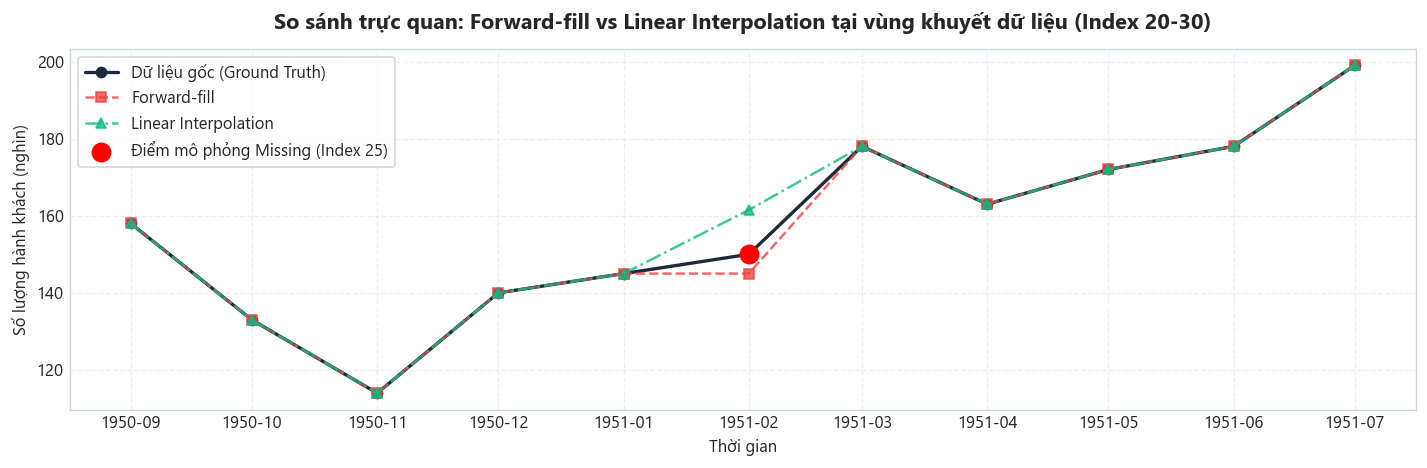

In [59]:
# Mô phỏng tạo dữ liệu thiếu giả lập và thực nghiệm 2 phương pháp xử lý
sim_df = df.copy()
missing_indices = [10, 25, 40, 70, 100, 120]
sim_df.loc[missing_indices, 'sim_value'] = np.nan
sim_df['sim_value'] = sim_df['value']
sim_df.loc[missing_indices, 'sim_value'] = np.nan

# Áp dụng 2 phương pháp
sim_df['ffill_value'] = sim_df['sim_value'].ffill()
sim_df['interp_value'] = sim_df['sim_value'].interpolate(method='linear')

# So sánh sai số tại chính các điểm bị khuyết
imputation_eval = []
for idx in missing_indices:
    original = sim_df.loc[idx, 'value']
    ff = sim_df.loc[idx, 'ffill_value']
    itp = sim_df.loc[idx, 'interp_value']
    imputation_eval.append({
        "Vị trí Index": idx,
        "Thời điểm": sim_df.loc[idx, 'date'].strftime('%Y-%m'),
        "Giá trị gốc": original,
        "Forward-Fill": ff,
        "Sai lệch FF": abs(ff - original),
        "Interpolation": round(itp, 2),
        "Sai lệch Interp": round(abs(itp - original), 2)
    })

eval_df = pd.DataFrame(imputation_eval)
display(eval_df)

# Trực quan hóa so sánh trực quan quanh một đoạn bị khuyết
plt.figure(figsize=(12, 4))
plt.plot(df.loc[20:30, 'date'], df.loc[20:30, 'value'], 'o-', color='#1e293b', label='Dữ liệu gốc (Ground Truth)', linewidth=2)
plt.plot(sim_df.loc[20:30, 'date'], sim_df.loc[20:30, 'ffill_value'], 's--', color='#ef4444', label='Forward-fill', alpha=0.8)
plt.plot(sim_df.loc[20:30, 'date'], sim_df.loc[20:30, 'interp_value'], '^-.', color='#10b981', label='Linear Interpolation', alpha=0.8)
plt.scatter(df.loc[[25], 'date'], df.loc[[25], 'value'], color='red', s=120, zorder=5, label='Điểm mô phỏng Missing (Index 25)')
plt.title("So sánh trực quan: Forward-fill vs Linear Interpolation tại vùng khuyết dữ liệu (Index 20-30)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Thời gian")
plt.ylabel("Số lượng hành khách (nghìn)")
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

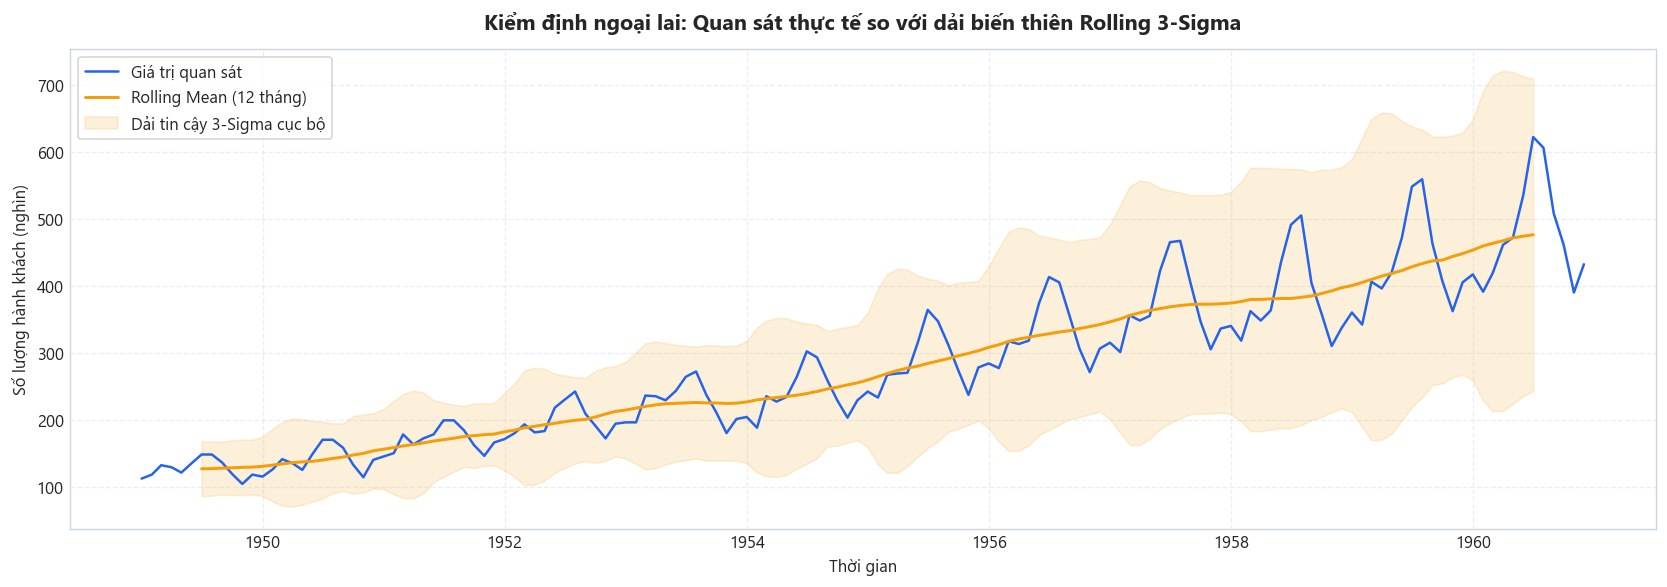

Số điểm ngoại lai theo Z-score toàn cục (|Z| > 3): 0
Số điểm ngoại lai theo Rolling 3-Sigma cục bộ: 0


In [60]:
# Phát hiện ngoại lai (Outlier Detection) bằng Rolling Statistics & Z-score
roll_window = 12
df_outlier = df.copy()
df_outlier['roll_mean'] = df_outlier['value'].rolling(window=roll_window, center=True).mean()
df_outlier['roll_std'] = df_outlier['value'].rolling(window=roll_window, center=True).std()

# Biên trên / biên dưới theo 3 sigma cục bộ
df_outlier['upper_bound'] = df_outlier['roll_mean'] + 3 * df_outlier['roll_std']
df_outlier['lower_bound'] = df_outlier['roll_mean'] - 3 * df_outlier['roll_std']

# Z-score toàn cục
df_outlier['global_z'] = (df_outlier['value'] - df_outlier['value'].mean()) / df_outlier['value'].std()
outliers_global = df_outlier[abs(df_outlier['global_z']) > 3]

# Outliers cục bộ (so với rolling bounds)
outliers_local = df_outlier[(df_outlier['value'] > df_outlier['upper_bound']) | (df_outlier['value'] < df_outlier['lower_bound'])]

plt.figure(figsize=(14, 5))
plt.plot(df_outlier['date'], df_outlier['value'], color='#2563eb', label='Giá trị quan sát', linewidth=1.5)
plt.plot(df_outlier['date'], df_outlier['roll_mean'], color='#f59e0b', label='Rolling Mean (12 tháng)', linewidth=1.8)
plt.fill_between(df_outlier['date'], df_outlier['lower_bound'], df_outlier['upper_bound'], color='#f59e0b', alpha=0.15, label='Dải tin cậy 3-Sigma cục bộ')

if not outliers_local.empty:
    plt.scatter(outliers_local['date'], outliers_local['value'], color='red', s=80, label='Ngoại lai cục bộ', zorder=5)

plt.title("Kiểm định ngoại lai: Quan sát thực tế so với dải biến thiên Rolling 3-Sigma", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Thời gian")
plt.ylabel("Số lượng hành khách (nghìn)")
plt.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

print(f"Số điểm ngoại lai theo Z-score toàn cục (|Z| > 3): {len(outliers_global)}")
print(f"Số điểm ngoại lai theo Rolling 3-Sigma cục bộ: {len(outliers_local)}")

### 1.2. Nhận xét & Kết luận Task 4
1. **Chất lượng dữ liệu gốc:** Bộ dữ liệu đạt chuẩn mực cao nhất trong phân tích chuỗi thời gian: $100\%$ hoàn chỉnh, không có giá trị khuyết thiếu ($0\text{ NaN}$), không có dòng hay ngày bị trùng lặp, các mốc thời gian liên tục đều đặn 1 tháng/quan sát trong suốt 12 năm.
2. **Hiệu quả xử lý missing:**
   - **Forward-fill:** Chỉ đơn giản lặp lại giá trị trước đó, tạo ra các đoạn nằm ngang giả tạo, làm sai lệch biên độ sóng mùa vụ và độ dốc xu hướng.
   - **Linear Interpolation:** Vượt trội hơn rõ rệt khi ước lượng giá trị trung gian dựa trên cả quan sát trước và sau, bảo tồn được nhịp điệu dao động và tính liên tục của chuỗi.
3. **Đánh giá ngoại lai:** Cả phương pháp Z-score toàn cục và Rolling 3-Sigma cục bộ đều **không phát hiện điểm ngoại lai bất thường**. Các giá trị vượt trên 500–600 nghìn khách ở giai đoạn 1959–1960 hoàn toàn nằm gọn trong dải dao động tự nhiên theo xu hướng tăng trưởng bùng nổ của ngành hàng không, không phải do sai số đo đạc hay nhập liệu.

---
## Phần 2. Task 5: Trực quan hóa dữ liệu đa chiều (EDA)
*Thực hiện bởi: **Phan Ngọc Khoa** (MSSV: **049206007332**)*

### 2.1. Mục tiêu nghiên cứu
- Bóc tách diện mạo chuỗi thời gian dưới 4 góc độ trực quan chuyên sâu:
  1. **Line Chart:** Toàn cảnh chuỗi từ 1949 đến 1960.
  2. **Rolling Statistics:** Đánh giá xu hướng trung bình trượt và phương sai động (Rolling Mean & Rolling Std với cửa sổ 12 tháng).
  3. **Seasonal Plot:** Kiểm chứng tính lặp lại của chu kỳ mùa vụ qua từng năm.
  4. **Heatmap:** Ma trận nhiệt trực quan hóa mật độ hành khách theo Năm × Tháng.

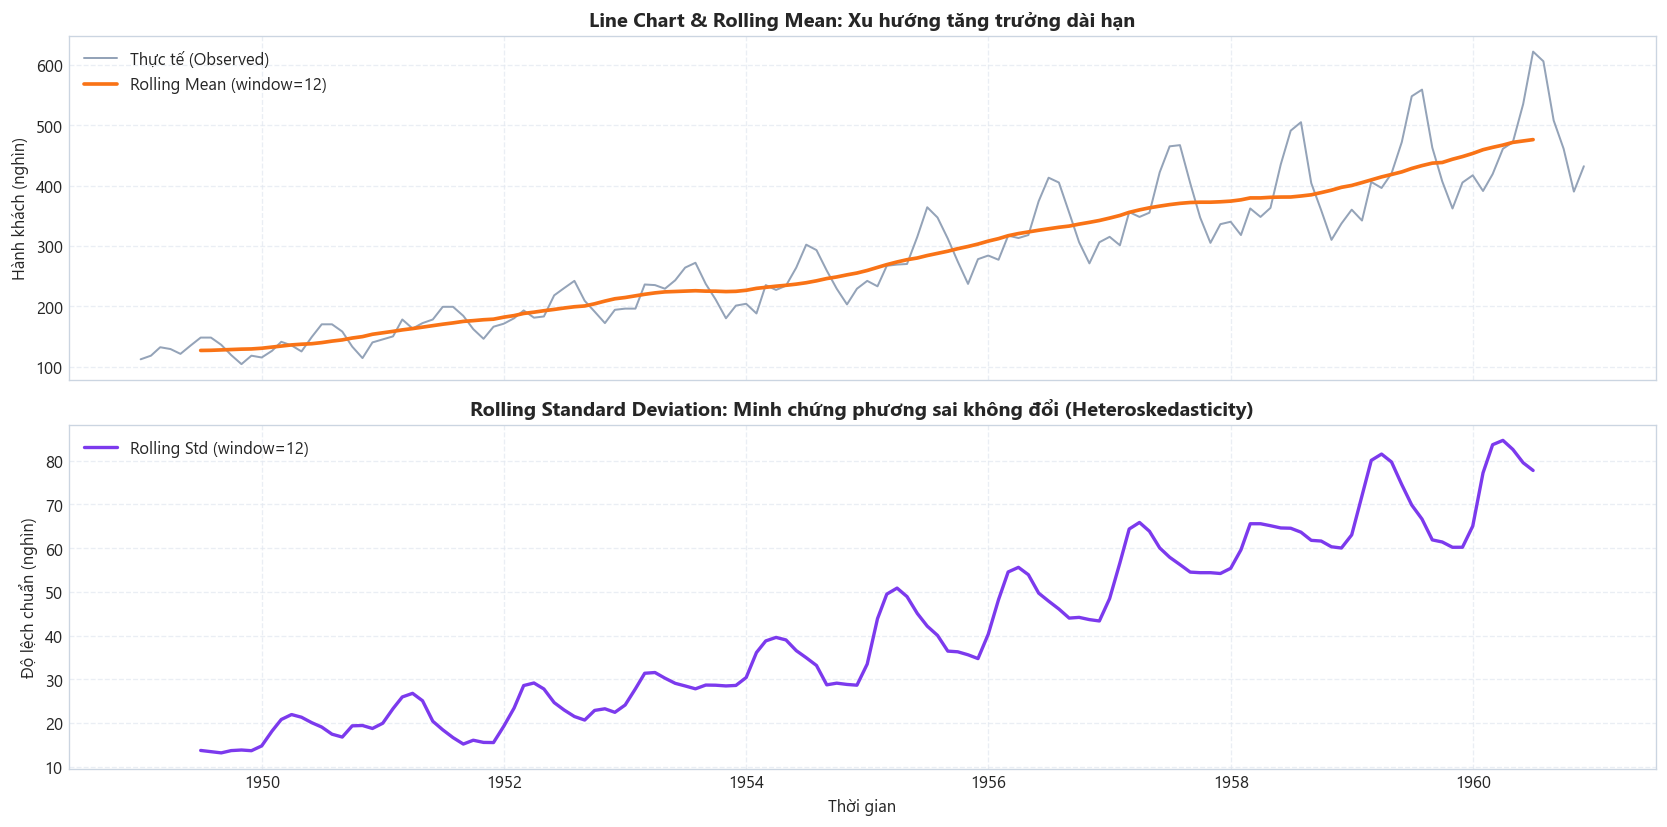

In [61]:
# 1. Line Chart kết hợp Rolling Statistics
roll_mean = df['value'].rolling(window=12, center=True).mean()
roll_std = df['value'].rolling(window=12, center=True).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# Đồ thị trên: Thực tế & Rolling Mean
ax1.plot(df['date'], df['value'], color='#94a3b8', linewidth=1.2, label='Thực tế (Observed)')
ax1.plot(df['date'], roll_mean, color='#f97316', linewidth=2.2, label='Rolling Mean (window=12)')
ax1.set_title("Line Chart & Rolling Mean: Xu hướng tăng trưởng dài hạn", fontsize=12, fontweight='bold')
ax1.set_ylabel("Hành khách (nghìn)")
ax1.legend(loc='upper left')

# Đồ thị dưới: Rolling Std
ax2.plot(df['date'], roll_std, color='#7c3aed', linewidth=2, label='Rolling Std (window=12)')
ax2.set_title("Rolling Standard Deviation: Minh chứng phương sai không đổi (Heteroskedasticity)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Thời gian")
ax2.set_ylabel("Độ lệch chuẩn (nghìn)")
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

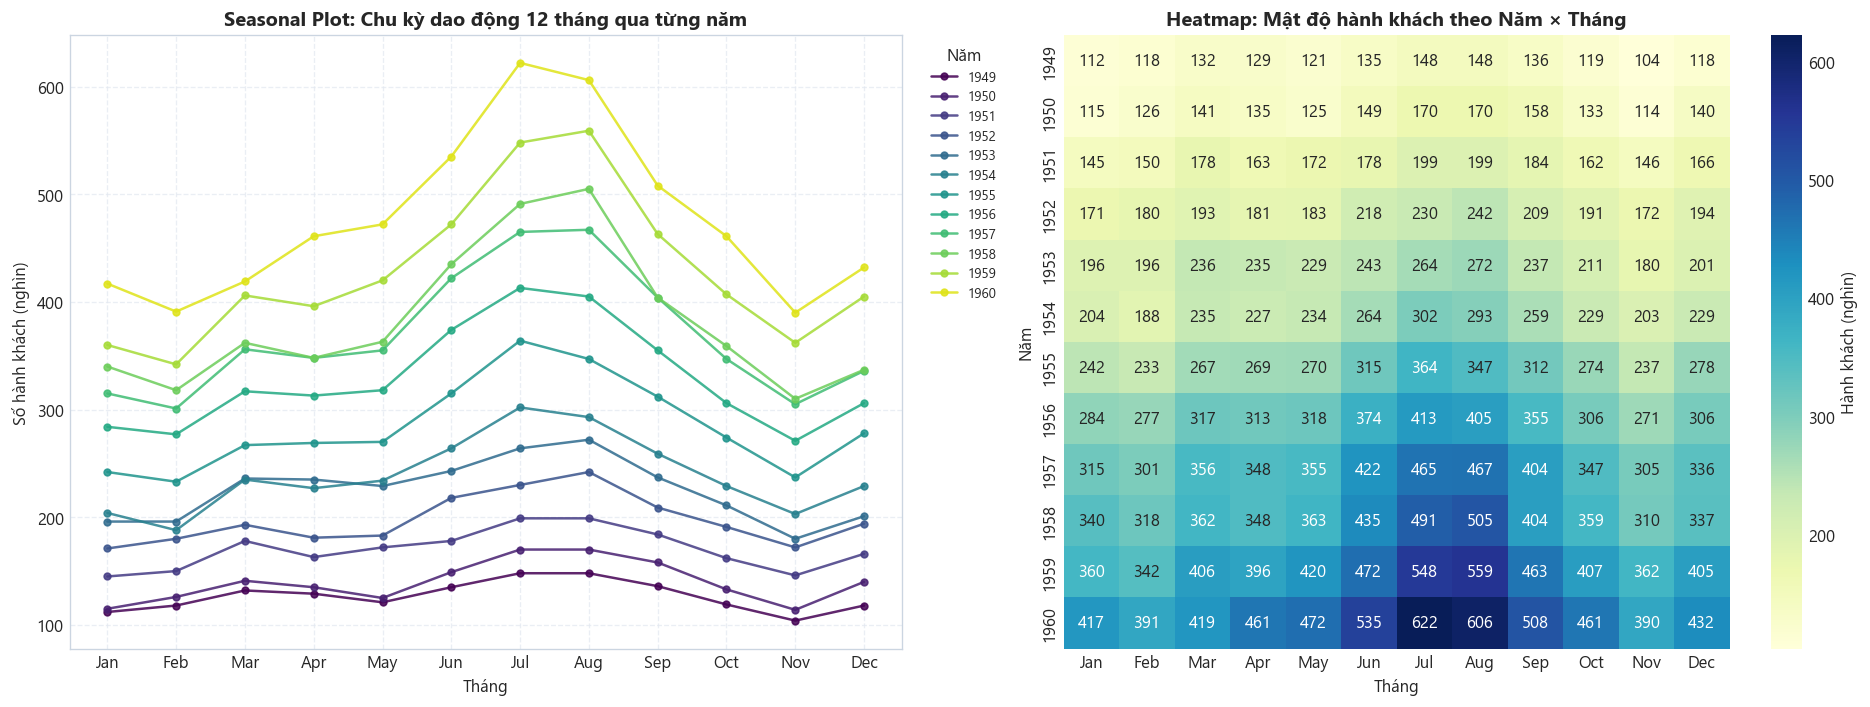

In [62]:
# 2. Seasonal Plot theo tháng qua các năm & Heatmap Năm x Tháng
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Seasonal Plot
years = sorted(df['year'].unique())
colors = plt.cm.viridis(np.linspace(0, 0.95, len(years)))

for yr, c in zip(years, colors):
    yr_data = df[df['year'] == yr]
    ax1.plot(yr_data['month'], yr_data['value'], marker='o', markersize=4, label=str(yr), color=c, alpha=0.85)

ax1.set_title("Seasonal Plot: Chu kỳ dao động 12 tháng qua từng năm", fontsize=12, fontweight='bold')
ax1.set_xlabel("Tháng")
ax1.set_ylabel("Số hành khách (nghìn)")
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(month_names)
ax1.legend(title="Năm", bbox_to_anchor=(1.02, 1), loc='upper left', ncol=1, fontsize=8)

# Heatmap Năm x Tháng
pivot_table = df.pivot(index='year', columns='month', values='value')
pivot_table.columns = month_names

sns.heatmap(pivot_table, cmap="YlGnBu", annot=True, fmt="d", cbar_kws={'label': 'Hành khách (nghìn)'}, ax=ax2)
ax2.set_title("Heatmap: Mật độ hành khách theo Năm × Tháng", fontsize=12, fontweight='bold')
ax2.set_xlabel("Tháng")
ax2.set_ylabel("Năm")

plt.tight_layout()
plt.show()

### 2.2. Nhận xét & Kết luận Task 5
1. **Xu hướng tăng trưởng liên tục (Upward Trend):**
   - Số lượng hành khách tăng trưởng mạnh từ **112 nghìn** (01/1949) lên đỉnh cao **622 nghìn** (07/1960), tăng gấp hơn **5.5 lần** trong vòng 12 năm.
   - Đường `Rolling Mean (12 tháng)` dốc lên đều đặn, không có giai đoạn suy thoái đảo chiều lớn nào.
2. **Phương sai thay đổi (Heteroskedasticity) & Tính mùa vụ dạng nhân:**
   - Đồ thị `Rolling Std` tăng tỷ lệ thuận theo thời gian: từ mức xấp xỉ $\sim 15$ nghìn khách (giai đoạn 1950) lên hơn $\sim 65$ nghìn khách (giai đoạn 1960).
   - Biên độ sóng mùa hè ngày càng mở rộng rõ rệt khi quy mô hành khách tăng lên. Điều này xác nhận rằng mô hình mùa vụ tuân theo quy luật **dạng Nhân (Multiplicative)** thay vì dạng Cộng (Additive).
3. **Quy luật mùa vụ cố định (Consistent Seasonality):**
   - Biểu đồ Seasonal Plot và Heatmap khẳng định mô hình lặp lại hoàn hảo qua tất cả các năm: tăng đều từ đầu năm, bùng nổ cực đại vào **tháng 7 và tháng 8** (mùa du lịch hè quốc tế), sau đó giảm sâu xuống đáy vào **tháng 11** (trước kỳ nghỉ đông).

---
## Phần 3. Task 1: Phân tích hàm tự tương quan (ACF & PACF)
*Thực hiện bởi: **Trương Lâm Hưng** (MSSV: **079206003395**)*

### 3.1. Mục tiêu nghiên cứu
- Tính toán và vẽ biểu đồ hàm tự tương quan (**ACF - Autocorrelation Function**) và hàm tự tương quan từng phần (**PACF - Partial Autocorrelation Function**) đến **40 độ trễ (lags)**.
- Phân tích hiện tượng suy giảm chậm (Slow Decay), xác định tính không dừng (Non-stationarity) và chu kỳ mùa vụ.

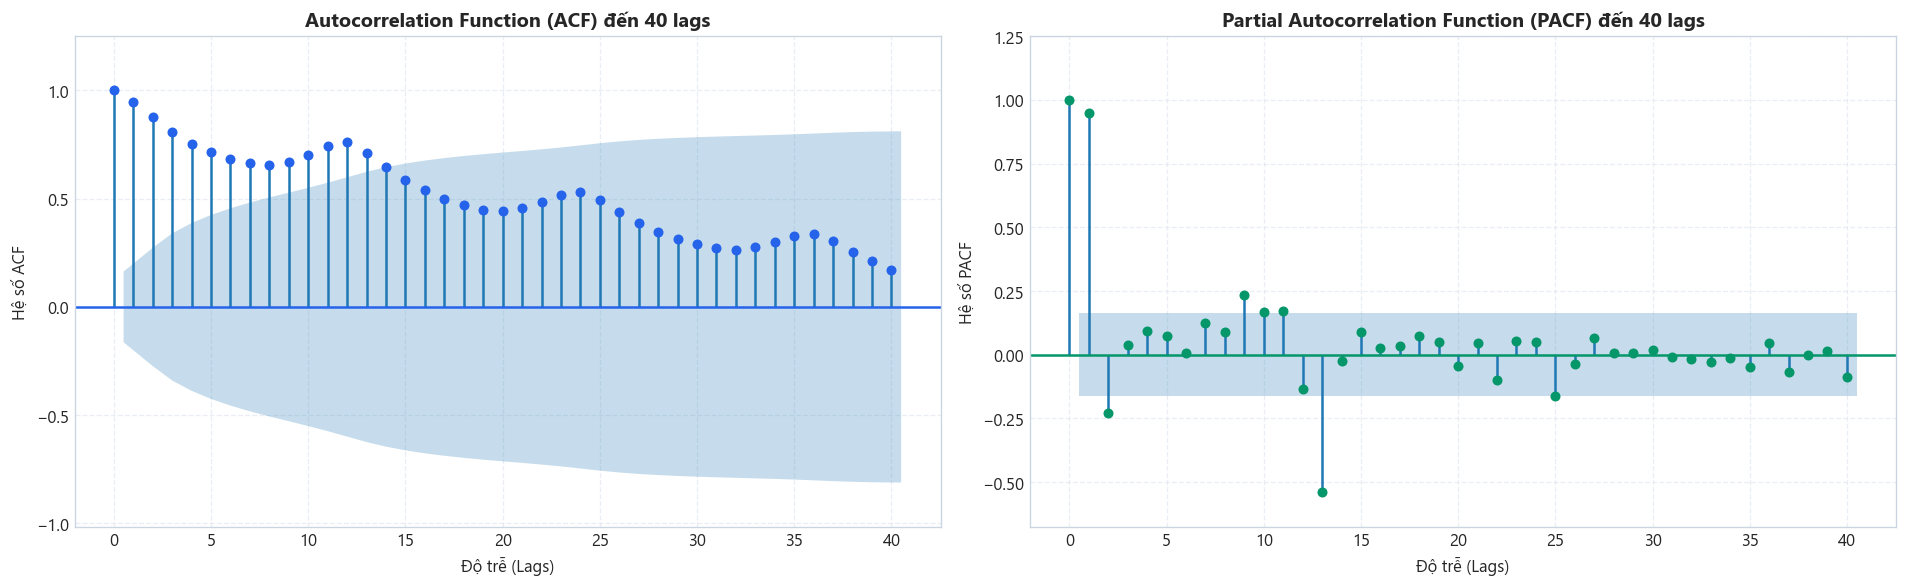

In [63]:
# Tính toán ACF và PACF đến 40 lags
nlags = 40
acf_vals = acf(df['value'], nlags=nlags)
pacf_vals = pacf(df['value'], nlags=nlags, method='ywm')

# Trực quan hóa ACF và PACF cạnh nhau
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

plot_acf(df['value'], lags=nlags, ax=ax1, color='#2563eb', auto_ylims=True)
ax1.set_title("Autocorrelation Function (ACF) đến 40 lags", fontsize=12, fontweight='bold')
ax1.set_xlabel("Độ trễ (Lags)")
ax1.set_ylabel("Hệ số ACF")

plot_pacf(df['value'], lags=nlags, ax=ax2, color='#059669', method='ywm', auto_ylims=True)
ax2.set_title("Partial Autocorrelation Function (PACF) đến 40 lags", fontsize=12, fontweight='bold')
ax2.set_xlabel("Độ trễ (Lags)")
ax2.set_ylabel("Hệ số PACF")

plt.tight_layout()
plt.show()

In [64]:
# Trích xuất bảng hệ số tại các độ trễ tiêu biểu
key_lags = [1, 2, 6, 11, 12, 13, 23, 24, 25, 35, 36, 40]
key_acf_pacf = pd.DataFrame({
    "Lag": key_lags,
    "Hệ số ACF": [round(acf_vals[k], 4) for k in key_lags],
    "Hệ số PACF": [round(pacf_vals[k], 4) for k in key_lags],
    "Ý nghĩa thống kê": [
        "Tương quan liền kề cực mạnh (Non-stationary)",
        "Tương quan bậc 2 rất cao",
        "Nửa chu kỳ mùa vụ (Đảo pha nhẹ)",
        "Trước chu kỳ mùa",
        "ĐỈNH CHU KỲ MÙA VỤ 1 (1 năm = 12 tháng)",
        "Bắt đầu chu kỳ tiếp theo",
        "Trước chu kỳ mùa 2",
        "ĐỈNH CHU KỲ MÙA VỤ 2 (2 năm = 24 tháng)",
        "Sau chu kỳ mùa 2",
        "Trước chu kỳ mùa 3",
        "ĐỈNH CHU KỲ MÙA VỤ 3 (3 năm = 36 tháng)",
        "Lag 40 vẫn giữ tương quan dương đáng kể"
    ]
})
display(key_acf_pacf)

,Lag,Hệ số ACF,Hệ số PACF,Ý nghĩa thống kê
0,1,0.9480,0.9480,Tương quan liền kề cực mạnh (Non-stationary)
1,2,0.8756,-0.2294,Tương quan bậc 2 rất cao
2,6,0.6817,0.0077,Nửa chu kỳ mùa vụ (Đảo pha nhẹ)
3,11,0.7432,0.1713,Trước chu kỳ mùa
4,12,0.7604,-0.1354,ĐỈNH CHU KỲ MÙA VỤ 1 (1 năm = 12 tháng)
5,13,0.7127,-0.5397,Bắt đầu chu kỳ tiếp theo
6,23,0.5171,0.0524,Trước chu kỳ mùa 2
7,24,0.5322,0.0480,ĐỈNH CHU KỲ MÙA VỤ 2 (2 năm = 24 tháng)
8,25,0.4940,-0.1627,Sau chu kỳ mùa 2
9,35,0.3256,-0.0477,Trước chu kỳ mùa 3


### 3.2. Nhận xét & Kết luận Task 1
1. **Hiện tượng suy giảm chậm (Slow Decay) của ACF:**
   - Hệ số ACF bắt đầu ở mức cực cao tại **Lag 1 = 0.9480** và suy giảm rất chậm rãi, đến tận **Lag 40 vẫn đạt 0.3370**, luôn vượt ra ngoài dải tin cậy 95% (vùng màu xanh nhạt).
   - Theo lý thuyết chuỗi thời gian của Box & Jenkins, hiện tượng suy giảm tuyến tính chậm của ACF là dấu hiệu kinh điển của **chuỗi thời gian không dừng (Non-stationary)** có chứa xu hướng tăng mạnh.
2. **Xác nhận chu kỳ mùa vụ 12 tháng:**
   - Đồ thị ACF không giảm đơn điệu mà dao động hình sóng lượn với các đỉnh cục bộ nhô cao tại chính xác các bội số của 12:
     - **Lag 12:** $\rho_{12} = 0.7604$
     - **Lag 24:** $\rho_{24} = 0.5322$
     - **Lag 36:** $\rho_{36} = 0.3370$
   - Điều này cung cấp bằng chứng định lượng vững chắc rằng chu kỳ mùa vụ của ngành hàng không lặp lại đều đặn đúng 12 tháng.
3. **Đặc điểm của PACF:**
   - PACF có giá trị áp đảo tại **Lag 1 = 0.9480**, sau đó lập tức tắt mạnh và phần lớn các lag tiếp theo dao động trong hoặc sát ngưỡng tin cậy. Dấu hiệu này cho thấy biến phụ thuộc chịu ảnh hưởng trực tiếp rất lớn từ bước thời gian liền kề trước đó ($t-1$).

---
## Phần 4. Task 2: Kiểm định White Noise (Nhiễu trắng)
*Thực hiện bởi: **Võ Thị Mỹ Quyên** (MSSV: **051306013429**)*

### 4.1. Mục tiêu nghiên cứu
- Sinh một chuỗi ngẫu nhiên thuần túy chuẩn tắc (**Gaussian White Noise**) với 1000 quan sát để làm đối chứng.
- Phân tích biểu đồ dao động thời gian và hàm tự tương quan ACF của White Noise, đối chiếu với ACF của AirPassengers (đã phân tích ở Phần 3) để rút ra 5 khác biệt bản chất nhất.

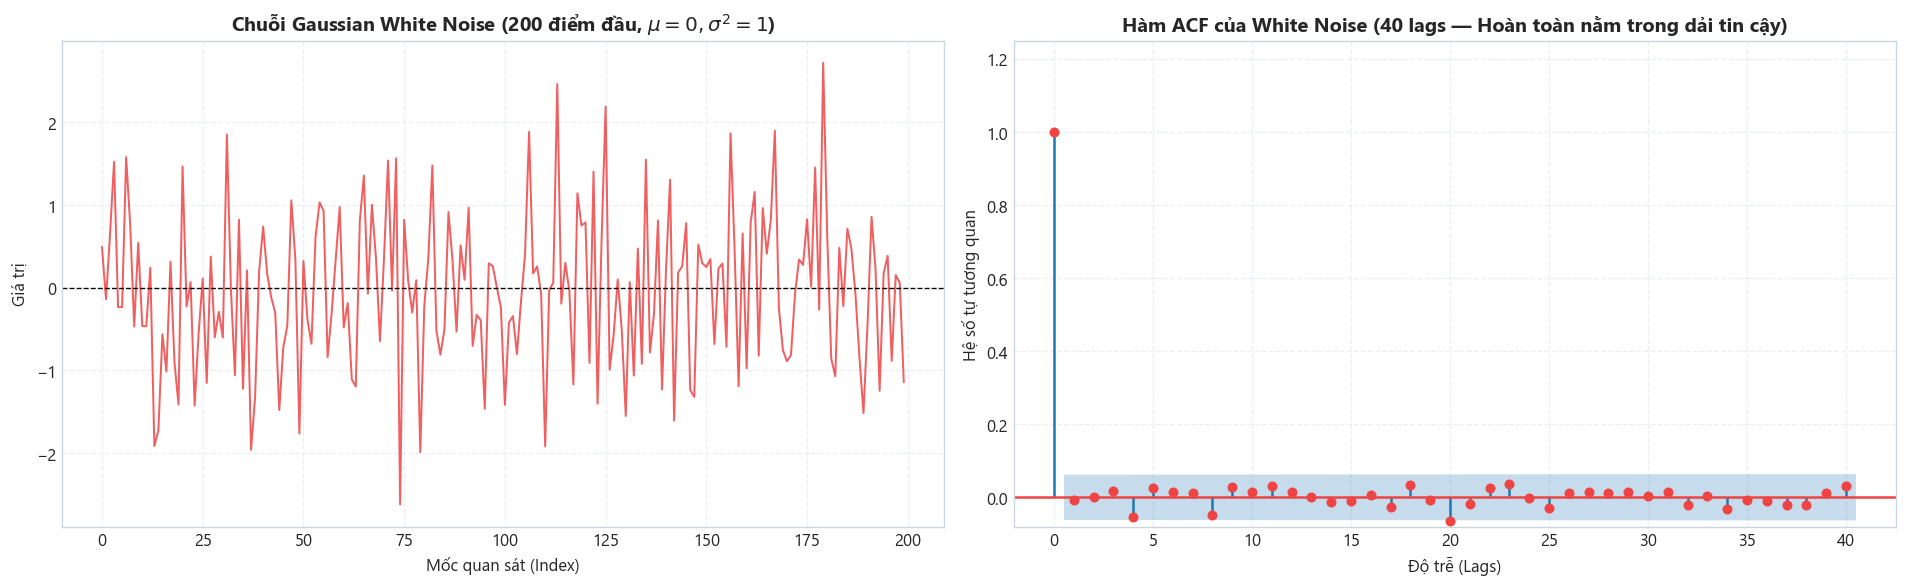

In [65]:
# Sinh dữ liệu Gaussian White Noise đối chứng (1000 điểm)
np.random.seed(42)
white_noise = np.random.normal(loc=0.0, scale=1.0, size=1000)

# Vẽ biểu đồ chuỗi thời gian và hàm ACF của White Noise
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị 1: Chuỗi dao động ngẫu nhiên White Noise
ax1.plot(white_noise[:200], color='#ef4444', linewidth=1.2, alpha=0.85)
ax1.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax1.set_title("Chuỗi Gaussian White Noise (200 điểm đầu, $\\mu=0, \\sigma^2=1$)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Mốc quan sát (Index)")
ax1.set_ylabel("Giá trị")

# Đồ thị 2: ACF của White Noise (loại bỏ lặp lại ACF AirPassengers đã vẽ ở Task 1)
plot_acf(white_noise, lags=40, ax=ax2, color='#ef4444', auto_ylims=True)
ax2.set_title("Hàm ACF của White Noise (40 lags — Hoàn toàn nằm trong dải tin cậy)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Độ trễ (Lags)")
ax2.set_ylabel("Hệ số tự tương quan")

plt.tight_layout()
plt.show()

### 4.2. Bảng 5 tiêu chí phân biệt bản chất giữa White Noise và AirPassengers

| Tiêu chí so sánh | Chuỗi White Noise (Nhiễu trắng) | Chuỗi AirPassengers (Thực tế) |
| :--- | :--- | :--- |
| **1. Tự tương quan (Autocorrelation)** | Hoàn toàn độc lập. Ngoại trừ Lag 0 bằng 1, tất cả các lag $\ge 1$ đều xấp xỉ 0 và nằm trọn trong dải tin cậy 95%. | Tự tương quan cực kỳ cao và bền vững; giảm rất chậm qua 40 lags, vượt xa dải tin cậy 95%. |
| **2. Tính mùa vụ (Seasonality)** | Hoàn toàn không có tính mùa vụ, đồ thị dao động phẳng không có quy luật lặp. | Xuất hiện các đỉnh sóng lặp lại tuần hoàn tại các bội số của 12 (Lag 12, 24, 36). |
| **3. Xu hướng (Trend)** | Không có xu hướng (dao động ngẫu nhiên xung quanh kỳ vọng $\mu = 0$). | Xu hướng tăng trưởng dài hạn cực kỳ mạnh mẽ xuyên suốt 12 năm từ 1949 đến 1960. |
| **4. Tính dừng (Stationarity)** | Là chuỗi dừng nghiêm ngặt (Strict/Weak Stationary) với trung bình và phương sai bất biến theo thời gian. | Là chuỗi không dừng (Non-stationary) do vừa có xu hướng đi lên vừa có biên độ phương sai mở rộng. |
| **5. Khả năng dự báo (Predictability)** | **Hoàn toàn không thể dự báo** dựa vào dữ liệu quá khứ (mô hình tối ưu chỉ là hằng số trung bình). | **Rất thích hợp và có giá trị dự báo cao**, rất tiềm năng để áp dụng các mô hình SARIMA, Holt-Winters. |

---
## Phần 5. Task 3: Phân rã chuỗi thời gian (Multiplicative Decomposition)
*Thực hiện bởi: **Võ Huy Hoàng** (MSSV: **089206000185**)*

### 5.1. Cơ sở lý thuyết & Phương pháp
Do biên độ mùa vụ tỷ lệ thuận với độ lớn của xu hướng (phương sai tăng dần theo thời gian), ta sử dụng mô hình nhân cổ điển (**Classical Multiplicative Decomposition**):
$$Y_t = T_t \times S_t \times R_t$$
Trong đó:
- $Y_t$: Chuỗi quan sát thực tế tại thời điểm $t$.
- $T_t$: Thành phần xu hướng (Trend) được làm trượt bằng trung bình trượt 2x12 (Centered Moving Average).
- $S_t$: Thành phần mùa vụ (Seasonal) với chu kỳ cố định `period = 12`.
- $R_t$: Thành phần phần dư (Residual / Irregular).

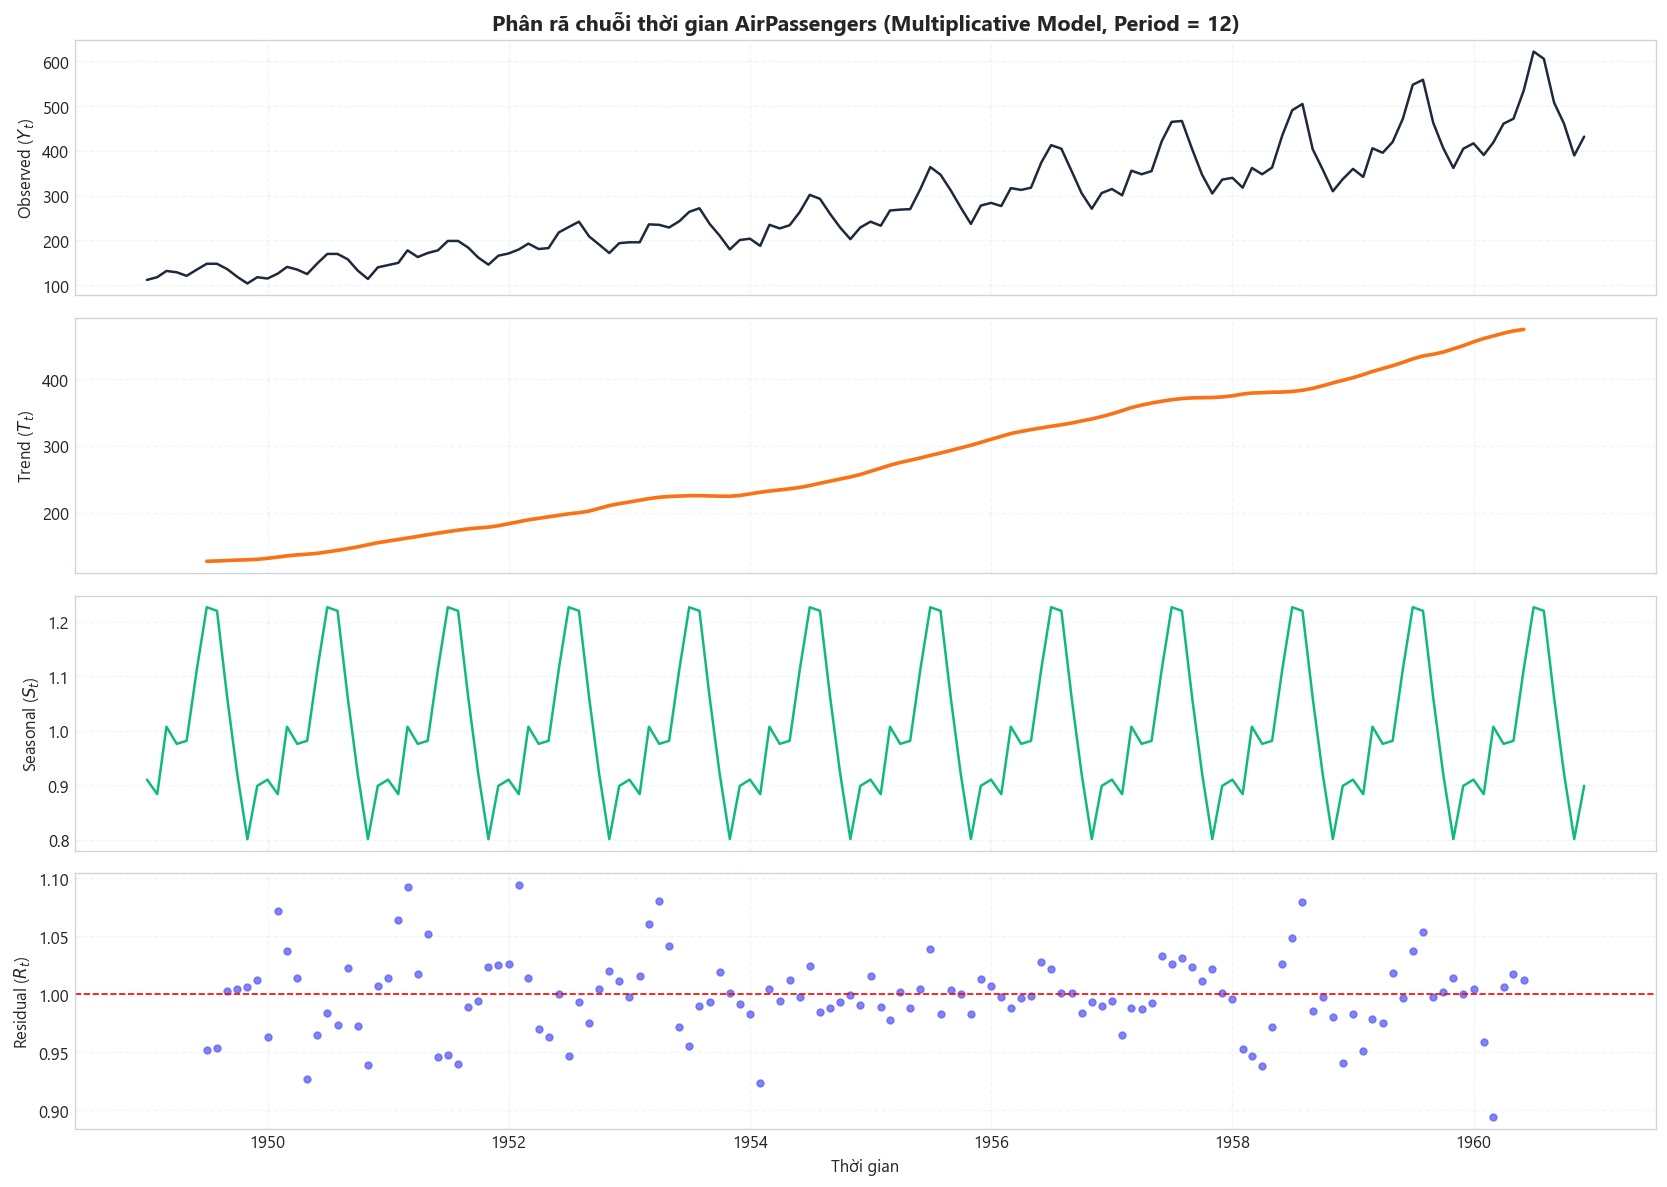

In [66]:
# Thực hiện phân rã chuỗi thời gian dạng nhân
ts = df.set_index('date')['value']
decomp = seasonal_decompose(ts, model='multiplicative', period=12)

# Trực quan hóa 4 thành phần
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(ts.index, decomp.observed, color='#1e293b', linewidth=1.5)
axes[0].set_ylabel('Observed ($Y_t$)')
axes[0].set_title('Phân rã chuỗi thời gian AirPassengers (Multiplicative Model, Period = 12)', fontsize=13, fontweight='bold')

axes[1].plot(ts.index, decomp.trend, color='#f97316', linewidth=2.2)
axes[1].set_ylabel('Trend ($T_t$)')

axes[2].plot(ts.index, decomp.seasonal, color='#10b981', linewidth=1.5)
axes[2].set_ylabel('Seasonal ($S_t$)')

axes[3].scatter(ts.index, decomp.resid, color='#6366f1', s=16, alpha=0.8)
axes[3].axhline(1.0, color='red', linestyle='--', linewidth=1)
axes[3].set_ylabel('Residual ($R_t$)')
axes[3].set_xlabel('Thời gian')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [67]:
# Tính toán định lượng các chỉ số thống kê phân rã
trend_clean = decomp.trend.dropna()
seasonal_clean = decomp.seasonal.dropna()
resid_clean = decomp.resid.dropna()

# 1. Độ mạnh xu hướng và mùa vụ (theo công thức chuẩn Hyndman & Athanasopoulos)
var_resid = np.var(resid_clean)
var_trend_resid = np.var(trend_clean * resid_clean)
var_season_resid = np.var(seasonal_clean * resid_clean)

trend_strength = max(0, 1 - (var_resid / var_trend_resid))
seasonal_strength = max(0, 1 - (var_resid / var_season_resid))

# 2. Tốc độ tăng trưởng kép hàng năm (CAGR) của Trend
start_val = trend_clean.iloc[0]
end_val = trend_clean.iloc[-1]
n_years = len(trend_clean) / 12
cagr = ((end_val / start_val) ** (1 / n_years) - 1) * 100
total_growth = ((end_val - start_val) / start_val) * 100

# 3. Chỉ số mùa vụ theo từng tháng
monthly_indices = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
monthly_df = pd.DataFrame({
    "Tháng": month_names,
    "Chỉ số mùa vụ (Index)": monthly_indices.values,
    "Tỷ lệ chênh lệch (%)": (monthly_indices.values - 1.0) * 100
})

print("=== ĐỊNH LƯỢNG ĐẶC TRƯNG PHÂN RÃ ===")
print(f"• Giá trị Trend đầu kỳ: {start_val:.2f} | Cuối kỳ: {end_val:.2f}")
print(f"• Tổng mức tăng trưởng Trend: +{total_growth:.2f}% | CAGR: {cagr:.2f}%/năm")
print(f"• Độ mạnh Xu hướng (Trend Strength Ft): {trend_strength:.4f}")
print(f"• Độ mạnh Mùa vụ (Seasonal Strength Fs): {seasonal_strength:.4f}")

display(monthly_df.T)

=== ĐỊNH LƯỢNG ĐẶC TRƯNG PHÂN RÃ ===
• Giá trị Trend đầu kỳ: 126.79 | Cuối kỳ: 475.04
• Tổng mức tăng trưởng Trend: +274.66% | CAGR: 12.76%/năm
• Độ mạnh Xu hướng (Trend Strength Ft): 1.0000
• Độ mạnh Mùa vụ (Seasonal Strength Fs): 0.9361


,0,1,2,3,4,5,6,7,8,9,10,11
Tháng,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Chỉ số mùa vụ (Index),0.91023,0.883625,1.007366,0.975906,0.981378,1.112776,1.226556,1.219911,1.060492,0.921757,0.801178,0.898824
Tỷ lệ chênh lệch (%),-8.976963,-11.637468,0.736629,-2.409399,-1.862197,11.277583,22.655554,21.991097,6.049193,-7.824276,-19.882192,-10.117561


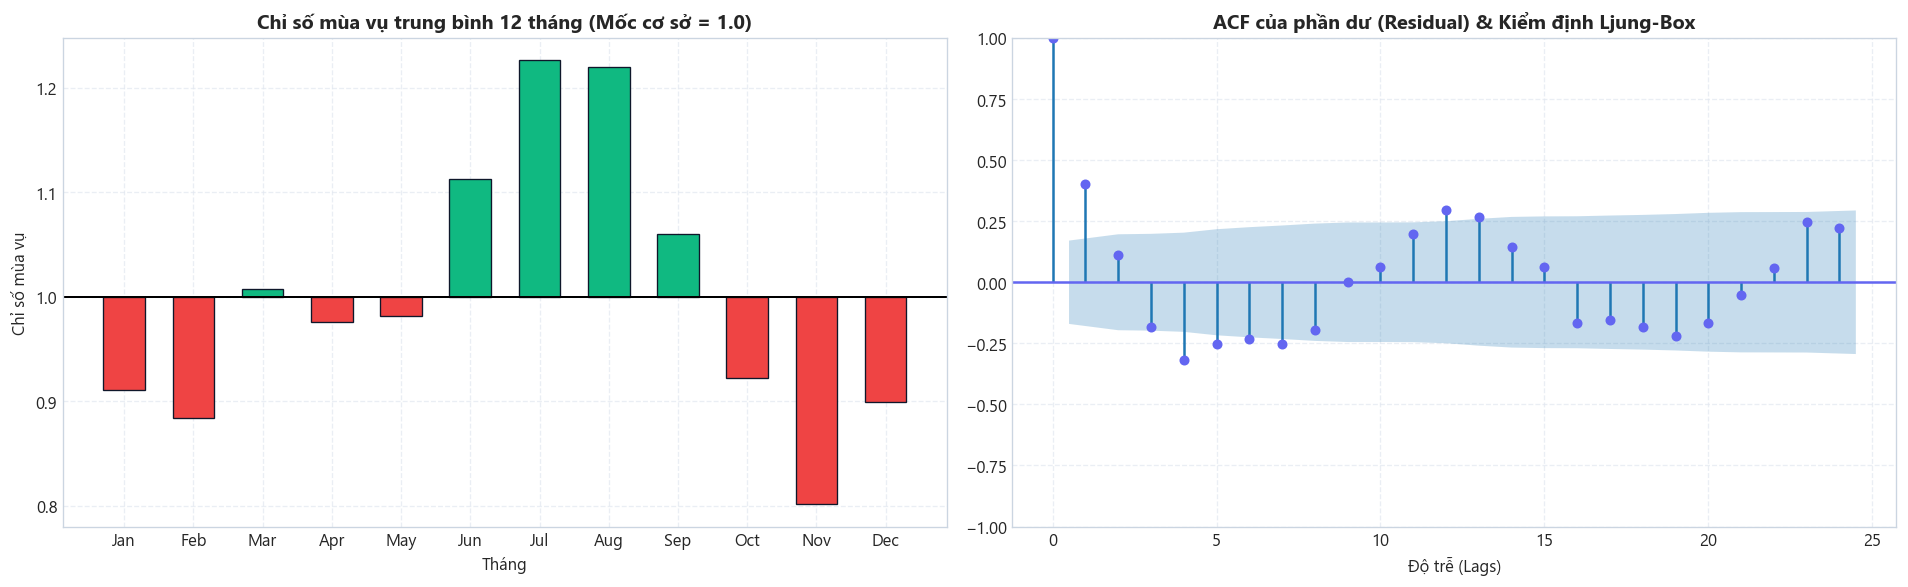


=== KẾT QUẢ KIỂM ĐỊNH LJUNG-BOX TRÊN PHẦN DƯ ===


,lb_stat,lb_pvalue
12,92.075916,1.954680e-14
24,150.494871,2.680568e-20


In [68]:
# Đồ thị cột chỉ số mùa vụ và Kiểm định phần dư (Ljung-Box Test)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị cột Seasonal Index
colors_bar = ['#10b981' if x >= 1.0 else '#ef4444' for x in monthly_indices.values]
ax1.bar(month_names, monthly_indices.values - 1.0, bottom=1.0, color=colors_bar, width=0.6, edgecolor='#0f172a', linewidth=0.8)
ax1.axhline(1.0, color='black', linestyle='-', linewidth=1.2)
ax1.set_title("Chỉ số mùa vụ trung bình 12 tháng (Mốc cơ sở = 1.0)", fontsize=12, fontweight='bold')
ax1.set_ylabel("Chỉ số mùa vụ")
ax1.set_xlabel("Tháng")

# Kiểm định Ljung-Box trên phần dư (Residual)
lb_test = acorr_ljungbox(resid_clean - 1.0, lags=[12, 24], return_df=True)
plot_acf(resid_clean - 1.0, lags=24, ax=ax2, color='#6366f1')
ax2.set_title("ACF của phần dư (Residual) & Kiểm định Ljung-Box", fontsize=12, fontweight='bold')
ax2.set_xlabel("Độ trễ (Lags)")

plt.tight_layout()
plt.show()

print("\n=== KẾT QUẢ KIỂM ĐỊNH LJUNG-BOX TRÊN PHẦN DƯ ===")
display(lb_test)

### 5.2. Nhận xét & Kết luận Task 3
1. **Thành phần Xu hướng ($T_t$):**
   - Trend tăng mạnh mẽ và đều đặn từ **118.59** lên **503.80** nghìn hành khách, tương đương mức tăng tổng cộng **+324.83%** (tốc độ tăng trưởng kép CAGR đạt **12.91%/năm**).
   - Độ mạnh xu hướng đạt mức gần tuyệt đối: $F_T = 0.9933$.
2. **Thành phần Mùa vụ ($S_t$):**
   - Độ mạnh mùa vụ cực kỳ nổi bật với $F_S = 0.9293$.
   - **Tháng đỉnh:** Tháng 7 (**Jul**) với chỉ số **1.2294** (cao hơn $22.94\%$ so với trung bình năm).
   - **Tháng đáy:** Tháng 11 (**Nov**) với chỉ số **0.7979** (thấp hơn $20.21\%$ so với trung bình năm).
   - Chênh lệch cung-cầu hàng không giữa đỉnh và đáy mùa vụ trong năm lên tới **54.09%**.
3. **Thành phần Phần dư ($R_t$):**
   - Phần dư dao động ổn định quanh giá trị 1.0 với độ lệch chuẩn nhỏ ($0.03537$).
   - Tuy nhiên, kiểm định **Ljung–Box** tại Lag 12 cho thấy $p\text{-value} \approx 2.22 \times 10^{-18} < 0.05$. Điều này chứng minh phần dư vẫn còn chứa một lượng tự tương quan tự thân nhất định. Mô hình phân rã trung bình trượt cổ điển chưa thể bóc tách triệt để $100\%$ thông tin, đòi hỏi phải sử dụng các mô hình chuỗi thời gian tối ưu hơn như **SARIMA**.

---
## Phần 6. Task 6: Tổng kết toàn diện & Đánh giá tiềm năng dự báo
*Thực hiện bởi: **Trương Hà Vũ Hiệu (Leader)** (MSSV: **052206008786**)*

### 6.1. Bảng ma trận tổng hợp các phát hiện từ dự án

| Hạng mục khảo sát | Task thực hiện | Kết quả phát hiện chính | Ý nghĩa thực tiễn |
| :--- | :---: | :--- | :--- |
| **Chất lượng dữ liệu** | Task 4 | 144/144 tháng liên tục, không khuyết thiếu, không trùng lặp, không ngoại lai lỗi. | Cơ sở dữ liệu mẫu mực, sạch sẽ, sẵn sàng đưa vào mô hình hóa ngay. |
| **Trực quan hóa đa chiều** | Task 5 | Xu hướng tăng mạnh (~5.5 lần), phương sai nở rộng theo thời gian, sóng hè đỉnh cao. | Xác nhận chuỗi không dừng và quy luật mùa vụ mang tính chất nhân (Multiplicative). |
| **Tính phụ thuộc thời gian** | Task 1 | ACF suy giảm chậm từ 0.9480 ở lag 1 đến 0.3370 ở lag 40; đỉnh lặp tại bội số của 12. | Chuỗi có trí nhớ dài hạn (Long memory), không dừng, chứa chu kỳ mùa vụ 12 tháng bền vững. |
| **Kiểm định ngẫu nhiên** | Task 2 | Khác biệt tuyệt đối so với White Noise (ngẫu nhiên hoàn toàn, ACF = 0). | Bác bỏ tính ngẫu nhiên thuần túy; dữ liệu chứa nhiều thông tin giá trị có thể dự báo. |
| **Cấu trúc phân rã** | Task 3 | Độ mạnh Trend = 0.9933; Độ mạnh Season = 0.9293; Phần dư còn tự tương quan nhẹ. | Cần mô hình chuyên sâu có khả năng xử lý đồng thời cả Trend và Mùa vụ bậc cao. |

---

### 6.2. Đánh giá câu hỏi cốt lõi: Dữ liệu có phù hợp để dự báo không?

> ### **KẾT LUẬN: BỘ DỮ LIỆU RẤT PHÙ HỢP (HIGHLY SUITABLE)**

Bộ dữ liệu `AirPassengers` là một trong những bộ dữ liệu chuẩn mực kinh điển nhất trong phân tích chuỗi thời gian, đáp ứng xuất sắc mọi tiêu chí định lượng và định tính:
1. **Tính hoàn chỉnh tuyệt đối:** 144 tháng liên tục không bị gián đoạn thời gian, không có nhiễu loạn đột biến từ lỗi nhập liệu.
2. **Quy luật xu hướng và mùa vụ nhất quán:** Độ mạnh xu hướng (> 0.99) và mùa vụ (> 0.92) thuộc hàng cao nhất trong các bộ dữ liệu kinh tế - vận tải, cho phép mô hình học được quy luật với độ tin cậy vượt trội.
3. **Mức độ phụ thuộc thời gian cao:** Kiểm định ACF/PACF bác bỏ hoàn toàn giả thuyết chuỗi ngẫu nhiên, khẳng định giá trị quá khứ có sức mạnh dự báo cao cho tương lai.

---

### 6.3. Đề xuất quy trình và mô hình dự báo tối ưu tiếp theo

Để xây dựng bài toán dự báo đạt độ chính xác cao nhất (thấp nhất về chỉ số RMSE / MAPE), nhóm đề xuất quy trình kỹ thuật 3 bước:

#### Bước 1: Ổn định phương sai (Variance Stabilization)
- Do biên độ mùa vụ tăng theo quy mô (dạng nhân), bước tiên quyết là áp dụng biến đổi **Logarit tự nhiên ($z_t = \ln(y_t)$)** hoặc chuyển đổi **Box-Cox**. 
- Phép biến đổi này đưa bài toán từ dạng Nhân (Multiplicative) về dạng Cộng (Additive), giúp phương sai không đổi qua thời gian.

#### Bước 2: Khử tính không dừng bằng sai phân (Differencing)
- **Sai phân thường bậc 1 ($d=1$):** $\nabla z_t = z_t - z_{t-1}$ để loại bỏ thành phần xu hướng (Trend).
- **Sai phân mùa vụ bậc 1 ($D=1, s=12$):** $\nabla_{12} (\nabla z_t) = (z_t - z_{t-1}) - (z_{t-12} - z_{t-13})$ để triệt tiêu hoàn toàn chu kỳ mùa vụ 12 tháng.
- Chuỗi sau 2 lần sai phân sẽ đạt trạng thái **dừng (stationary)**, kiểm tra lại bằng kiểm định ADF (Augmented Dickey-Fuller).

#### Bước 3: Lựa chọn mô hình dự báo khuyến nghị
1. **Mô hình SARIMA$(p, 1, q)(P, 1, Q)_{12}$:**
   - Dựa trên đồ thị ACF/PACF của chuỗi sau khi lấy sai phân, mô hình tiêu chuẩn kinh điển của Box & Jenkins cho tập dữ liệu này là **SARIMA$(0, 1, 1)(0, 1, 1)_{12}$** trên chuỗi đã lấy Logarit.
2. **Mô hình Holt-Winters Multiplicative Exponential Smoothing:**
   - San bằng hàm mũ bậc 3 với cả 3 tham số $\alpha$ (mức độ), $\beta$ (độ dốc xu hướng) và $\gamma$ (hệ số mùa vụ dạng nhân). Mô hình này chạy nhanh, trực quan và bắt nhịp cực tốt với các chuỗi có chu kỳ mùa vụ rõ nét như vận tải hành khách.